In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error


df = pd.read_csv('/content/airline-passengers (2) (1).csv')



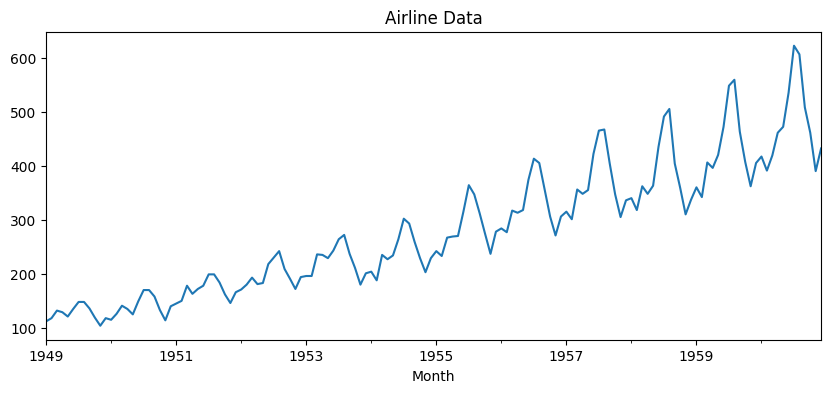

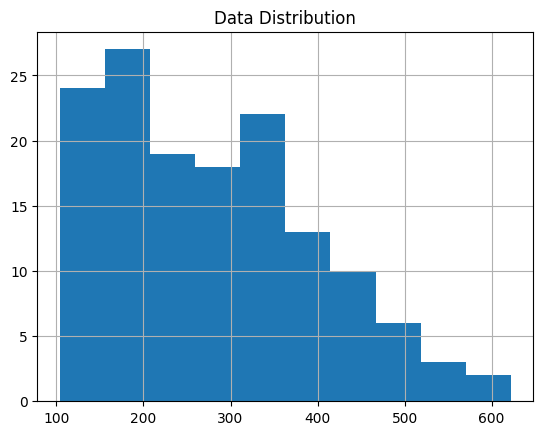

In [ ]:
df["Month"] = pd.to_datetime(df["Month"])
df.set_index("Month", inplace=True)

ts = df.iloc[:, 0].asfreq("MS")

ts.plot(title="Airline Data", figsize=(10, 4))
plt.show()

ts.hist()
plt.title("Data Distribution")
plt.show()

In [ ]:
result = adfuller(ts.dropna())

print("Original Data")
print("ADF Statistic:", result[0])
print("p-value:", result[1])

if result[1] <= 0.05:
    print("Data is stationary")
else:
    print("Data is not stationary")

result = adfuller(ts.diff().dropna())

print("\nAfter First Differencing")
print("ADF Statistic:", result[0])
print("p-value:", result[1])

if result[1] <= 0.05:
    print("Data is stationary")
else:
    print("Data is not stationary")

Original Data
ADF Statistic: 0.8153688792060498
p-value: 0.991880243437641
Data is not stationary

After First Differencing
ADF Statistic: -2.8292668241700047
p-value: 0.05421329028382478
Data is not stationary


/tmp/ipykernel_527/4170425083.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(ts.dropna())
/tmp/ipykernel_527/4170425083.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(ts.diff().dropna())


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


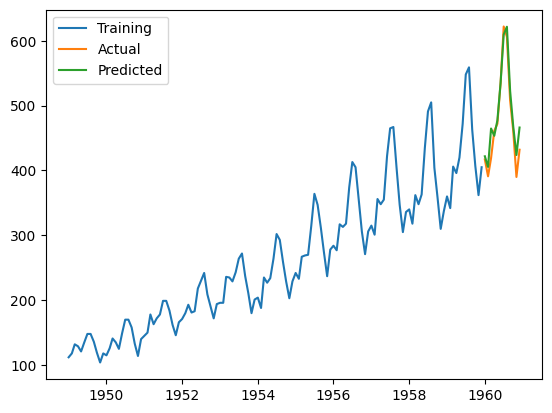

In [ ]:
train = ts[:-12]
test = ts[-12:]

model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12)
)

fit = model.fit(disp=False)
pred = fit.forecast(12)

plt.plot(train, label="Training")
plt.plot(test, label="Actual")
plt.plot(pred, label="Predicted")
plt.legend()
plt.show()


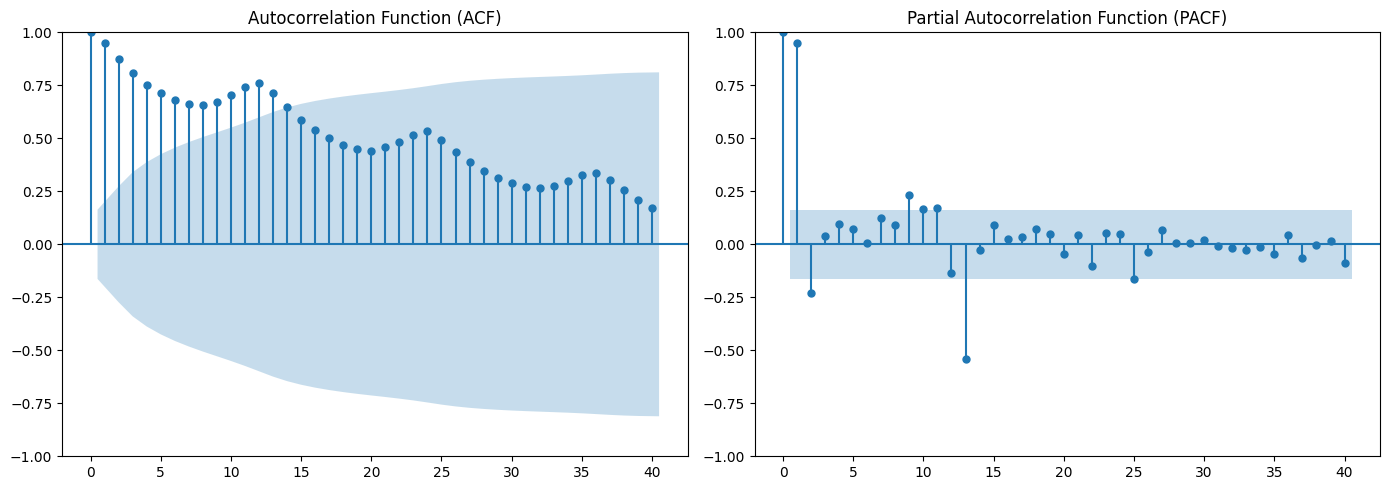

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(ts, lags=40, ax=axes[0])
axes[0].set_title("Autocorrelation Function (ACF)")

plot_pacf(ts, lags=40, ax=axes[1], method='ywm')
axes[1].set_title("Partial Autocorrelation Function (PACF)")

plt.tight_layout()
plt.show()

MAE: 16.313534458547483
MSE: 448.71161677588384
RMSE: 21.18281418451958


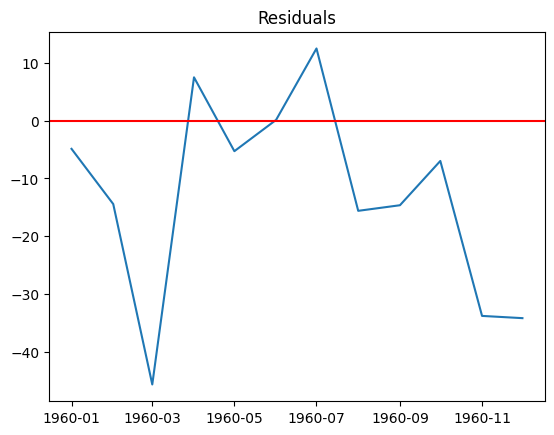

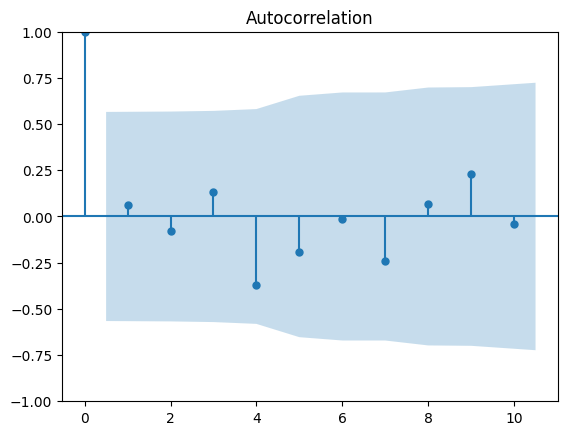

In [ ]:
print("MAE:", mean_absolute_error(test, pred))
print("MSE:", mean_squared_error(test, pred))
print("RMSE:", np.sqrt(mean_squared_error(test, pred)))

# Residual analysis
residuals = test - pred
plt.plot(residuals)
plt.axhline(0, color="red")
plt.title("Residuals")
plt.show()

plot_acf(residuals.dropna(), lags=10)
plt.show()

Next 5 Years Forecast:


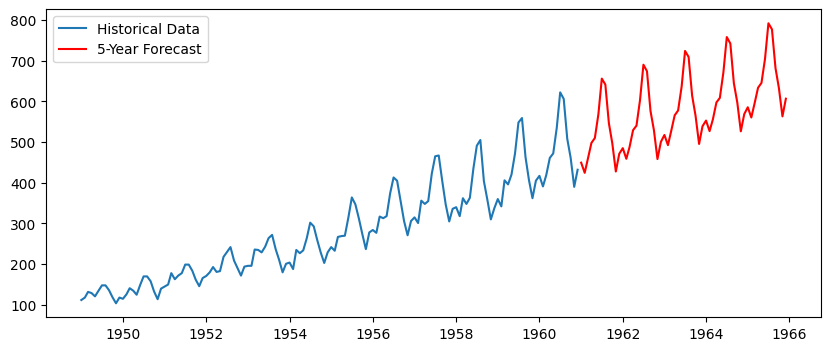

In [9]:
model = SARIMAX(
    ts,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12)
)

fit = model.fit(disp=False)
forecast = fit.forecast(60)

print("Next 5 Years Forecast:")
#print(forecast)

forecast.to_csv("airline_forecast.csv")

plt.figure(figsize=(10, 4))
plt.plot(ts, label="Historical Data")
plt.plot(forecast, color="red", label="5-Year Forecast")
plt.legend()
plt.show()